In [42]:
"""
Domain alignment script

- Aligns multispectral stacks from two years (2019 -> 2024) using CORAL or Procrustes.
- Uses stable pixels selected by cosine-distance between co-registered pixels.
- Reservoir sampling for D_cos percentile estimation (memory-bounded).
- Robust median-MAD scaling and reproducible RNG.
- Saves aligned scaled-space product and mapped-back raw product.
- Writes QA JSON and metadata joblib.

Author: Alex Mathew
Date: 19 November 2025
"""

import os
import json
import logging
from datetime import datetime

import numpy as np
from numpy.linalg import eigh, svd
import rasterio as rio
from rasterio.windows import Window
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.warp import transform_geom
from rasterio.crs import CRS
from tqdm import tqdm
from joblib import dump
import fiona
from fiona.transform import transform_geom as fiona_transform_geom
from sklearn.decomposition import PCA

In [43]:
# -----------------------------
# CONFIG / PATHS
# -----------------------------
DATA_2019 = r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2019.tif"
DATA_2024 = r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"
OUTDIR    = r"C:\Users\snvra\NISAR_Data_project\Outputs\Coral"
os.makedirs(OUTDIR, exist_ok=True)

STUDY_SHP = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\eastBound\eastBound.shp"
WATER_SHP = r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\mask_2024\mask_2024.shp"

TILE = 1024
STABLE_Q = 2      # percentile for stable pixels
RIDGE = 1e-4         # covariance ridge for CORAL
ALIGN_METHOD = "coral"   # "coral" or "procrustes"

SEED = 42
RNG = np.random.default_rng(SEED)
MAX_Q_SAMPLE = 50000   # maximum number of D_cos values to keep for percentile estimation
MAX_STABLE_PER_WINDOW = 25_000  # max stable pixel samples saved per window
MAX_GLOBAL_STABLE = 50000   # global cap on stable samples to prevent OOM

# Output filenames (in OUTDIR)
STABLE_MASK_PATH = os.path.join(OUTDIR, "stable_mask.tif")
ALIGNED_SCALED_PATH = os.path.join(OUTDIR, "aligned_2019_in2024_scaled.tif")
ALIGNED_RAW_PATH = os.path.join(OUTDIR, "aligned_2019_in2024_raw.tif")
METADATA_JOBLIB = os.path.join(OUTDIR, f"align_metadata_{ALIGN_METHOD}.joblib")
QA_JSON = os.path.join(OUTDIR, "align_qa.json")

# TILE safety
if TILE <= 0:
    TILE = 512

In [44]:
# -----------------------------
# Logging
# -----------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    handlers=[logging.StreamHandler()]
)
log = logging.getLogger("domain_align")

# -----------------------------
# Helpers
# -----------------------------
def open_stack(path):
    ds = rio.open(path)
    if ds.count < 1:
        raise AssertionError(f"Expected >=1 band, got {ds.count} for {path}")
    return ds

def same_grid(a, b):
    return (a.crs == b.crs and
            a.transform.almost_equals(b.transform) and
            a.width == b.width and
            a.height == b.height)

def resample_to_match(src_path, ref_ds, out_path, resampling=Resampling.bilinear):
    """Resample src to ref grid and write to out_path."""
    with rio.open(src_path) as src:
        profile = src.profile.copy()
        profile.update({
            "crs": ref_ds.crs,
            "transform": ref_ds.transform,
            "width": ref_ds.width,
            "height": ref_ds.height,
            "dtype": src.dtypes[0]
        })
        with rio.open(out_path, "w", **profile) as dst:
            for b in range(1, src.count + 1):
                rio.warp.reproject(
                    source=rio.band(src, b),
                    destination=rio.band(dst, b),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=ref_ds.transform,
                    dst_crs=ref_ds.crs,
                    resampling=resampling
                )
    return out_path

def windows(ds, tile=TILE):
    """Generator of windows (streaming, no list materialization)."""
    for row in range(0, ds.height, tile):
        h = min(tile, ds.height - row)
        for col in range(0, ds.width, tile):
            w = min(tile, ds.width - col)
            yield Window(col_off=col, row_off=row, width=w, height=h)

# Robust scaling (Median–MAD)
def robust_fit(X, eps=1e-9):
    med = np.median(X, axis=0)
    mad = np.median(np.abs(X - med), axis=0)
    mad = np.where(mad < eps, eps, mad)
    return {"med": med.astype(np.float32), "mad": mad.astype(np.float32)}

def apply_robust(Y, params):
    return (Y - params["med"]) / params["mad"]

def invert_robust(Y_scaled, params):
    return Y_scaled * params["mad"] + params["med"]

# Cosine distance (efficient)
def cosine_distance(a, b, eps=1e-9):
    # a,b: [N, D]
    # handles potential tiny norms
    dot = np.einsum("ij,ij->i", a, b)
    na = np.linalg.norm(a, axis=1)
    nb = np.linalg.norm(b, axis=1)
    denom = (na * nb) + eps
    cos = dot / denom
    return 1.0 - np.clip(cos, -1.0, 1.0)

def cosine_distance_chunks(a, b, chunk=200_000):
    out = np.empty(a.shape[0], dtype=np.float64)
    i = 0
    while i < a.shape[0]:
        j = min(a.shape[0], i + chunk)
        out[i:j] = cosine_distance(a[i:j], b[i:j])
        i = j
    return out

# CORAL helpers (stable PSD sqrt/inv-sqrt)
def _sqrtm_psd(cov, eps=1e-10):
    w, v = eigh(cov + eps * np.eye(cov.shape[0]))
    w = np.clip(w, eps, None)
    return (v * np.sqrt(w)) @ v.T

def _invsqrtm_psd(cov, eps=1e-10):
    w, v = eigh(cov + eps * np.eye(cov.shape[0]))
    w = np.clip(w, eps, None)
    return (v * (1.0 / np.sqrt(w))) @ v.T

def coral_fit(X_src, X_tgt, ridge=RIDGE, ddof=0):
    mu_s = X_src.mean(0)
    mu_t = X_tgt.mean(0)
    Cs = np.cov(X_src, rowvar=False, ddof=ddof) + ridge * np.eye(X_src.shape[1])
    Ct = np.cov(X_tgt, rowvar=False, ddof=ddof) + ridge * np.eye(X_tgt.shape[1])
    As = _invsqrtm_psd(Cs)
    Bt = _sqrtm_psd(Ct)
    return {"mu_s": mu_s.astype(np.float32),
            "mu_t": mu_t.astype(np.float32),
            "As": As.astype(np.float32),
            "Bt": Bt.astype(np.float32)}

def coral_apply(X, params):
    return (X - params["mu_s"]) @ params["As"] @ params["Bt"] + params["mu_t"]

# Procrustes
def procrustes_fit(X_src, X_tgt):
    mu_s = X_src.mean(0); mu_t = X_tgt.mean(0)
    Xs = X_src - mu_s
    Xt = X_tgt - mu_t
    U, _, Vt = svd(Xs.T @ Xt, full_matrices=False)
    R = U @ Vt
    # avoid reflection if we want pure rotation
    if np.linalg.det(R) < 0:
        U[:, -1] *= -1
        R = U @ Vt
    return {"mu_s": mu_s.astype(np.float32), "mu_t": mu_t.astype(np.float32), "R": R.astype(np.float32)}

def procrustes_apply(X, params):
    return (X - params["mu_s"]) @ params["R"] + params["mu_t"]

# Geometry loader + reprojection
def load_and_reproject_geoms(shp_path, dst_crs):
    """Load geometries from shapefile and reproject them to dst_crs (rasterio CRS or string)."""
    geoms = []
    dst_crs_obj = CRS.from_user_input(dst_crs)
    if not os.path.exists(shp_path):
        raise FileNotFoundError(f"Shapefile not found: {shp_path}")
    with fiona.open(shp_path, "r") as src:
        src_crs = src.crs if src.crs else src.crs_wkt
        for feat in src:
            geom = feat["geometry"]
            if src_crs:
                try:
                    g2 = transform_geom(src_crs, dst_crs_obj.to_string(), geom, precision=6)
                except Exception:
                    # last resort, use original geometry (assume already in dst_crs)
                    g2 = geom
            else:
                g2 = geom
            geoms.append(g2)
    return geoms

# Reservoir sampling support for percentile estimation
def reservoir_add(reservoir_list, values, max_size, rng, total_seen):
    """Append values into reservoir_list using reservoir sampling; returns updated total_seen."""
    # reservoir_list: python list
    # values: 1D numpy array
    for v in values:
        total_seen += 1
        if len(reservoir_list) < max_size:
            reservoir_list.append(float(v))
        else:
            j = rng.integers(0, total_seen)
            if j < max_size:
                reservoir_list[j] = float(v)
    return total_seen


In [45]:
# -----------------------------
# OPEN & ALIGN GRIDS
# -----------------------------
log.info("Starting domain alignment script")

ds_ref = open_stack(DATA_2024)
ds_toMatch = open_stack(DATA_2019)

if not same_grid(ds_ref, ds_toMatch):
    log.info("Grids differ — resampling 2019 to 2024 grid...")
    data_2019_RES = os.path.join(OUTDIR, "emb_2019_resampled.tif")
    resample_to_match(DATA_2019, ds_ref, data_2019_RES, resampling=Resampling.bilinear)
    ds_toMatch.close()
    ds_toMatch = rio.open(data_2019_RES)

# -----------------------------
# Create study & water masks
# -----------------------------
log.info("Creating study-area and water masks from shapefiles...")
study_geoms = load_and_reproject_geoms(STUDY_SHP, ds_ref.crs)
water_geoms = load_and_reproject_geoms(WATER_SHP, ds_ref.crs)

inside_study = geometry_mask(study_geoms,
                             transform=ds_ref.transform,
                             invert=True,
                             out_shape=(ds_ref.height, ds_ref.width))

inside_water = geometry_mask(water_geoms,
                             transform=ds_ref.transform,
                             invert=True,
                             out_shape=(ds_ref.height, ds_ref.width))

processing_mask = inside_study & (~inside_water)
del inside_study, inside_water
log.info("Masks created")

# -----------------------------
# STABLE PIXELS BY D_cos (reservoir sampling)
# -----------------------------
log.info("Estimating D_cos threshold with reservoir sampling...")
q_reservoir = []
total_d_seen = 0

# iterate streaming windows (no list(...))
for w in tqdm(windows(ds_ref, TILE), desc="D_cos percentile sample"):
    A = ds_ref.read(window=w).astype(np.float32)
    B = ds_toMatch.read(window=w).astype(np.float32)
    A = np.moveaxis(A, 0, -1)
    B = np.moveaxis(B, 0, -1)

    rs, cs = w.toslices()
    mask_chunk = processing_mask[rs, cs]

    valid_geom = mask_chunk
    valid_data = np.isfinite(A).all(axis=-1) & np.isfinite(B).all(axis=-1)
    valid = valid_geom & valid_data

    if not valid.any():
        continue

    flatA = A.reshape(-1, A.shape[-1])
    flatB = B.reshape(-1, B.shape[-1])
    valid_idx = np.where(valid.ravel())[0]
    Asel = flatA[valid_idx]
    Bsel = flatB[valid_idx]

    # compute d in chunks if large
    if Asel.shape[0] > 300_000:
        d = cosine_distance_chunks(Asel, Bsel, chunk=200_000)
    else:
        d = cosine_distance(Asel, Bsel)

    # sample from d into reservoir (cap memory)
    if d.size > 50_000:
        sel_idx = RNG.choice(d.size, 50_000, replace=False)
        vals = d[sel_idx]
    else:
        vals = d
    total_d_seen = reservoir_add(q_reservoir, vals, MAX_Q_SAMPLE, RNG, total_d_seen)

if len(q_reservoir) == 0:
    raise RuntimeError("No valid pixels found for D_cos sampling. Check shapefiles and alignment.")

q_arr = np.array(q_reservoir, dtype=np.float64)
thr = float(np.percentile(q_arr, STABLE_Q))
log.info(f"D_cos threshold (percentile={STABLE_Q:.3f}): {thr:.6f}")

# -----------------------------
# Write stable mask and collect stable samples (streaming; with caps)
# -----------------------------
log.info("Collecting stable samples and writing stable mask...")
profile = ds_ref.profile.copy()
profile.update(count=1, dtype="uint8", nodata=0)

X24_stable_list = []
X19_stable_list = []
global_stable_count = 0

with rio.open(STABLE_MASK_PATH, "w", **profile) as dst_mask:
    for w in tqdm(windows(ds_ref, TILE), desc="Stable mask + samples"):
        A = ds_ref.read(window=w).astype(np.float32)
        B = ds_toMatch.read(window=w).astype(np.float32)
        A = np.moveaxis(A, 0, -1)
        B = np.moveaxis(B, 0, -1)

        rs, cs = w.toslices()
        mask_chunk = processing_mask[rs, cs]

        valid = mask_chunk & np.isfinite(A).all(axis=-1) & np.isfinite(B).all(axis=-1)
        flatA = A.reshape(-1, A.shape[-1])
        flatB = B.reshape(-1, B.shape[-1])

        vidx = np.where(valid.ravel())[0]
        if vidx.size == 0:
            dst_mask.write(np.zeros((A.shape[0], A.shape[1]), dtype=np.uint8), window=w, indexes=1)
            continue

        # compute distances only on valid rows
        if vidx.size > 300_000:
            # compute in chunks
            d = cosine_distance_chunks(flatA[vidx], flatB[vidx], chunk=200_000)
        else:
            d = cosine_distance(flatA[vidx], flatB[vidx])

        # produce full-window d array initialized to large
        d_full = np.full(flatA.shape[0], np.inf, dtype=d.dtype)
        d_full[vidx] = d
        d2 = d_full.reshape(A.shape[0], A.shape[1])

        # stable mask for this window
        m = ((d2 <= thr) & valid).astype(np.uint8)
        dst_mask.write(m, window=w, indexes=1)

        idx = np.where(m.ravel() == 1)[0]
        if idx.size > 0 and global_stable_count < MAX_GLOBAL_STABLE:
            take = min(MAX_STABLE_PER_WINDOW, idx.size)
            sel = RNG.choice(idx, take, replace=False)
            X24_stable_list.append(flatA[sel])
            X19_stable_list.append(flatB[sel])
            global_stable_count += take

log.info(f"Collected approx {global_stable_count:,} stable samples (capped to {MAX_GLOBAL_STABLE})")

if len(X24_stable_list) == 0 or len(X19_stable_list) == 0:
    raise RuntimeError("No stable samples collected after masking. Lower STABLE_Q or inspect masks/shapefiles.")

X24_stable = np.concatenate(X24_stable_list, axis=0)
X19_stable = np.concatenate(X19_stable_list, axis=0)
log.info(f"Stable samples shape: X24 {X24_stable.shape}, X19 {X19_stable.shape}")

# -----------------------------
# 2) FIT ROBUST SCALERS (year-wise on stable pixels)
# -----------------------------
log.info("Fitting robust (median-MAD) scalers on stable samples...")
sc24_params = robust_fit(X24_stable)
sc19_params = robust_fit(X19_stable)
dump({"sc24": sc24_params, "sc19": sc19_params}, os.path.join(OUTDIR, "scaler_params.joblib"))
log.info("Saved scaler parameters")

X24s = apply_robust(X24_stable, sc24_params)
X19s = apply_robust(X19_stable, sc19_params)

# -----------------------------
# 3) FIT ALIGNMENT (CORAL or Procrustes) ON SCALED STABLE SAMPLES
# -----------------------------
log.info(f"Fitting alignment method: {ALIGN_METHOD}")
if ALIGN_METHOD.lower() == "coral":
    align_params = coral_fit(X19s, X24s, ridge=RIDGE)
    align_kind = "coral"
elif ALIGN_METHOD.lower() == "procrustes":
    align_params = procrustes_fit(X19s, X24s)
    align_kind = "procrustes"
else:
    raise ValueError("ALIGN_METHOD must be 'coral' or 'procrustes'")

dump({"method": align_kind, "params": align_params}, METADATA_JOBLIB)
log.info(f"Saved alignment metadata to {METADATA_JOBLIB}")

# -----------------------------
# 4) APPLY ALIGNMENT TO FULL 2019 RASTER (WRITE TWO PRODUCTS)
#    A) aligned_2019_in_2024_scaled.tif (in 2024 scaled space)
#    B) aligned_2019_in_2024_raw.tif    (mapped back to 2024 raw space)
# -----------------------------
log.info("Applying alignment to full 2019 raster and writing outputs...")
profile64 = ds_ref.profile.copy()
profile64.update(count=ds_ref.count, dtype="float32", nodata=None, compress="deflate")

with rio.open(ALIGNED_SCALED_PATH, "w", **profile64) as dst_scaled, \
     rio.open(ALIGNED_RAW_PATH,    "w", **profile64) as dst_raw:

    for w in tqdm(windows(ds_toMatch, TILE), desc="Apply alignment to 2019"):
        arr19 = ds_toMatch.read(window=w).astype(np.float32)     # [bands,h,w]
        arr19_hw = np.moveaxis(arr19, 0, -1)                     # [h,w,bands]
        flat19   = arr19_hw.reshape(-1, arr19_hw.shape[-1])

        rs, cs = w.toslices()
        mask_chunk = processing_mask[rs, cs]
        if not mask_chunk.any():
            # Outside study: write raw product and also produce a scaled block (identity alignment)
            dst_raw.write(arr19, window=w)

            # Produce scaled unaligned (apply robust scaling only)
            flat19_s = apply_robust(flat19, sc19_params)
            block_scaled = flat19_s.reshape(arr19_hw.shape[0], arr19_hw.shape[1], arr19_hw.shape[-1])
            block_scaled = np.moveaxis(block_scaled, -1, 0).astype(np.float32)
            dst_scaled.write(block_scaled, window=w)
            continue

        # For inside-study windows: proceed normally
        flat19_s = apply_robust(flat19, sc19_params)

        # Align in scaled space
        if align_kind == "coral":
            flat_aligned_s = coral_apply(flat19_s, align_params)
        else:
            flat_aligned_s = procrustes_apply(flat19_s, align_params)

        # Write scaled-space aligned product
        block_scaled = flat_aligned_s.reshape(arr19_hw.shape[0], arr19_hw.shape[1], arr19_hw.shape[-1])
        block_scaled = np.moveaxis(block_scaled, -1, 0).astype(np.float32)  # [bands,h,w]
        dst_scaled.write(block_scaled, window=w)

        # Map back to 2024 RAW (inverse robust using sc24)
        flat_aligned_raw = invert_robust(flat_aligned_s, sc24_params)
        block_raw = flat_aligned_raw.reshape(arr19_hw.shape[0], arr19_hw.shape[1], arr19_hw.shape[-1])
        block_raw = np.moveaxis(block_raw, -1, 0).astype(np.float32)
        dst_raw.write(block_raw, window=w)

log.info(f"Wrote scaled aligned product: {ALIGNED_SCALED_PATH}")
log.info(f"Wrote raw mapped product:     {ALIGNED_RAW_PATH}")
log.info(f"Wrote stable mask:           {STABLE_MASK_PATH}")

# -----------------------------
# 5) QUICK QA: covariance gap before/after, per-band stats
# -----------------------------
def cov_gap(A, B):
    CA = np.cov(A, rowvar=False)
    CB = np.cov(B, rowvar=False)
    return float(np.linalg.norm(CA - CB, ord='fro'))

log.info("Computing QA statistics on stable samples...")
gap_before = cov_gap(X19s, X24s)
if align_kind == "coral":
    X19s_al = coral_apply(X19s, align_params)
else:
    X19s_al = procrustes_apply(X19s, align_params)
gap_after = cov_gap(X19s_al, X24s)

# per-band stats on raw stable samples
per_band_stats = []
for i in range(X24_stable.shape[1]):
    s24 = X24_stable[:, i]
    s19 = X19_stable[:, i]
    per_band_stats.append({
        "band": int(i + 1),
        "X24_median": float(np.median(s24)),
        "X24_mad": float(np.median(np.abs(s24 - np.median(s24)))),
        "X19_median": float(np.median(s19)),
        "X19_mad": float(np.median(np.abs(s19 - np.median(s19))))
    })

qa = {
    "date_utc": datetime.utcnow().isoformat() + "Z",
    "align_method": align_kind,
    "percentile for stable pixels": STABLE_Q,
    "D_cos_threshold": thr,
    "stable_sample_count": int(X24_stable.shape[0]),
    "seed": int(SEED),
    "cov_gap_before_scaled": gap_before,
    "cov_gap_after_scaled": gap_after,
    "per_band_stats": per_band_stats
}

with open(QA_JSON, "w") as fh:
    json.dump(qa, fh, indent=2)

log.info(f"QA saved to {QA_JSON}")
log.info("Domain alignment complete. Proceed to classification when ready.")

2026-06-29 11:42:36,893 [INFO] Starting domain alignment script
2026-06-29 11:42:37,039 [WARNING] CPLE_AppDefined in krishsatemb2024.tif: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
2026-06-29 11:42:37,158 [WARNING] CPLE_AppDefined in krishsatemb2019.tif: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
2026-06-29 11:42:37,965 [INFO] Creating study-area and water masks from shapefiles...
2026-06-29 11:42:52,357 [INFO] Masks created
2026-06-29 11:42:52,361 [INFO] Estimating D_cos threshold with reservoir sampling...
D_cos percentile sample: 9it [00:27,  3.03s/it]
2026-06-29 11:43:19,712 [INFO] D_cos threshold (percentile=2.000): 0.014274
2026-06-29 11:43:19,718 [INFO] Collecting stable samples and writing stable mask...
2026-06-29 11:43:19,853 [WARNING] CPLE_IllegalAr

In [46]:
import joblib

meta = joblib.load(r"C:\Users\snvra\NISAR_Data_project\Outputs\Coral\align_metadata_coral.joblib")

print(type(meta))

if isinstance(meta, dict):
    print(meta.keys())

<class 'dict'>
dict_keys(['method', 'params'])


In [47]:
import joblib
import pprint

print("Method:", meta["method"])

print("\nParams keys:")
print(meta["params"].keys())

for k, v in meta["params"].items():
    try:
        print(k, type(v), getattr(v, "shape", None))
    except:
        print(k, type(v))

Method: coral

Params keys:
dict_keys(['mu_s', 'mu_t', 'As', 'Bt'])
mu_s <class 'numpy.ndarray'> (64,)
mu_t <class 'numpy.ndarray'> (64,)
As <class 'numpy.ndarray'> (64, 64)
Bt <class 'numpy.ndarray'> (64, 64)


In [48]:
scaler = joblib.load(r"C:\Users\snvra\NISAR_Data_project\Outputs\Coral\scaler_params.joblib")

print(type(scaler))
print(scaler.keys())

<class 'dict'>
dict_keys(['sc24', 'sc19'])


(2236, 2102)
Unique values: {np.uint8(0), np.uint8(1)}


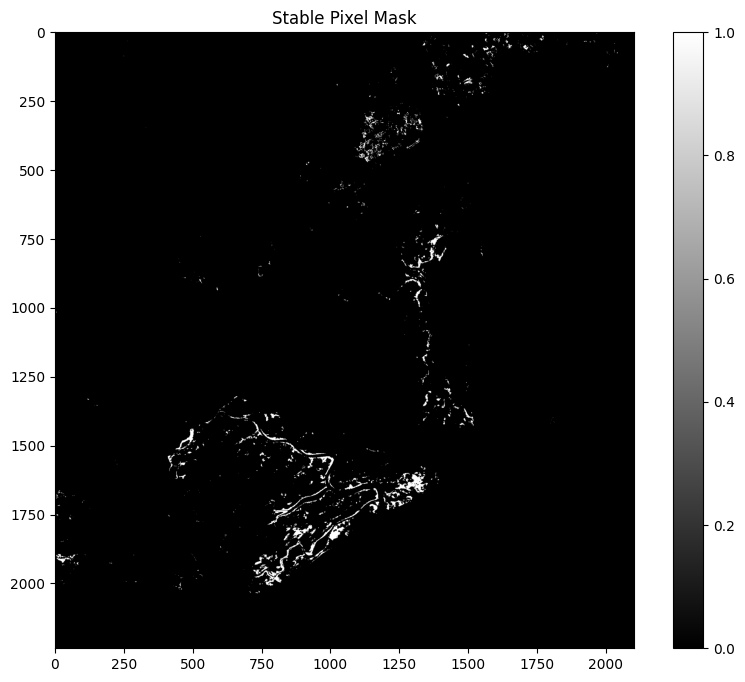

In [49]:
import rasterio
import matplotlib.pyplot as plt

stable_mask_path = r"C:\Users\snvra\NISAR_Data_project\Outputs\Coral\stable_mask.tif"

with rasterio.open(stable_mask_path) as src:
    mask = src.read(1)

print(mask.shape)
print("Unique values:", set(mask.flatten()))

plt.figure(figsize=(10,8))
plt.imshow(mask, cmap="gray")
plt.title("Stable Pixel Mask")
plt.colorbar()
plt.show()

In [50]:
import numpy as np

print("Stable pixels:", np.sum(mask > 0))
print("Total pixels:", mask.size)
print("Percentage:", 100*np.sum(mask > 0)/mask.size)

Stable pixels: 41937
Total pixels: 4700072
Percentage: 0.8922629270360114


2026-06-29 12:19:19,761 [WARNING] CPLE_AppDefined in krishsatemb2024.tif: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
2026-06-29 12:19:19,771 [WARNING] CPLE_AppDefined in TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


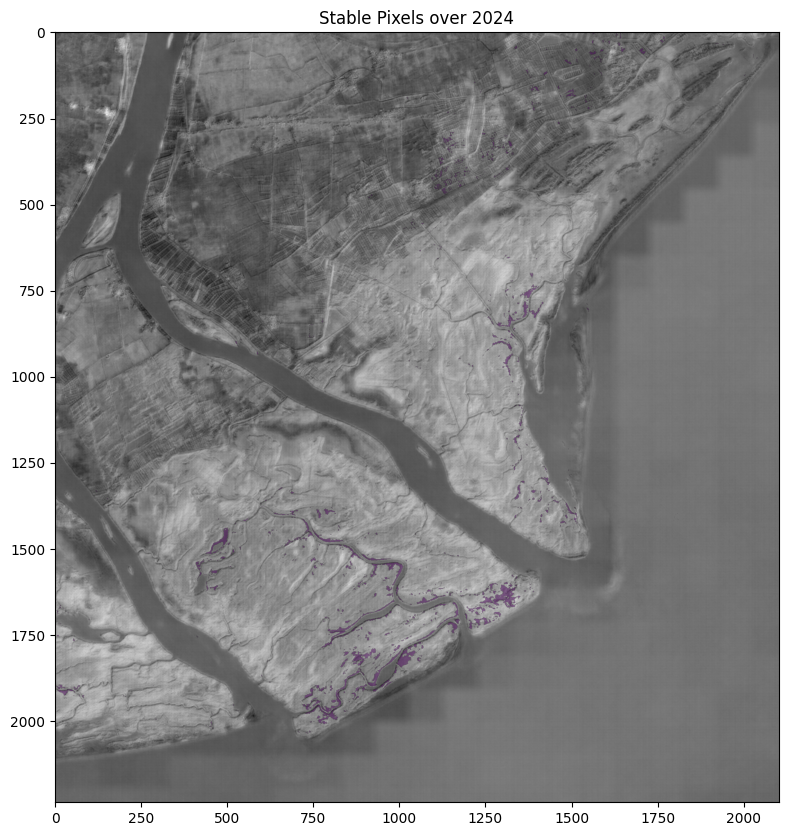

In [51]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

with rasterio.open(DATA_2024) as src:
    band = src.read(1)

with rasterio.open(stable_mask_path) as src:
    stable = src.read(1)

plt.figure(figsize=(12,10))
plt.imshow(band, cmap='gray')
plt.imshow(np.ma.masked_where(stable == 0, stable),
           alpha=0.5)
plt.title("Stable Pixels over 2024")
plt.show()

In [52]:
from sklearn.decomposition import PCA
import numpy as np

d = 10

# BEFORE
Ps = PCA(n_components=d).fit(X19s).components_.T
Pt = PCA(n_components=d).fit(X24s).components_.T

before = np.linalg.norm(Ps - Pt)

# AFTER CORAL
X19_coral = coral_apply(X19s, align_params)

Ps_coral = PCA(n_components=d).fit(X19_coral).components_.T

after = np.linalg.norm(Ps_coral - Pt)

print(f"Subspace distance BEFORE: {before:.6f}")
print(f"Subspace distance AFTER : {after:.6f}")

Subspace distance BEFORE: 4.519795
Subspace distance AFTER : 0.000272


In [53]:
def cov_gap(A, B):
    CA = np.cov(A, rowvar=False)
    CB = np.cov(B, rowvar=False)
    return np.linalg.norm(CA - CB, ord='fro')

In [54]:
cov_before = cov_gap(X19s, X24s)

print("Covariance gap BEFORE:", cov_before)

Covariance gap BEFORE: 18.443347393903537


In [55]:
X19_coral = coral_apply(X19s, align_params)

cov_after = cov_gap(X19_coral, X24s)

print("Covariance gap AFTER:", cov_after)

Covariance gap AFTER: 0.0017522239709131598


In [56]:
print(q_arr.shape)
print(q_arr.min(), q_arr.max())

(50000,)
0.006106257438659668 0.5071618556976318


In [57]:
import pandas as pd
import numpy as np

percentiles = np.arange(1, 101)

results = []

for q in percentiles:

    thr = np.percentile(q_arr, q)

    n = np.sum(q_arr <= thr)

    results.append({
        "percentile": q,
        "threshold": thr,
        "stable_pixels": n
    })

df = pd.DataFrame(results)

df.head()

,percentile,threshold,stable_pixels
0,1,0.012469,500
1,2,0.014274,1000
2,3,0.015488,1500
3,4,0.016524,2000
4,5,0.017443,2500


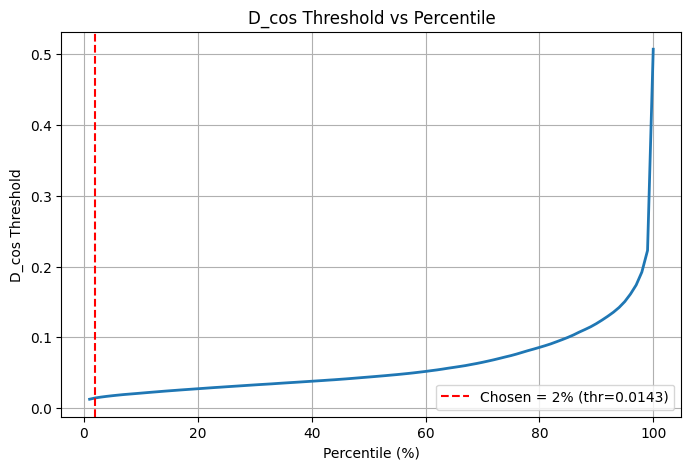

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(df["percentile"], df["threshold"], lw=2)

plt.axvline(
    2,
    color="red",
    linestyle="--",
    label=f"Chosen = 2% (thr={np.percentile(q_arr,2):.4f})"
)

plt.xlabel("Percentile (%)")
plt.ylabel("D_cos Threshold")
plt.title("D_cos Threshold vs Percentile")
plt.grid(True)
plt.legend()

plt.show()

In [59]:
print(type(d2))
print(d2.shape)

print(type(processing_mask))
print(processing_mask.shape)

<class 'numpy.ndarray'>
(188, 1024)
<class 'numpy.ndarray'>
(2236, 2102)


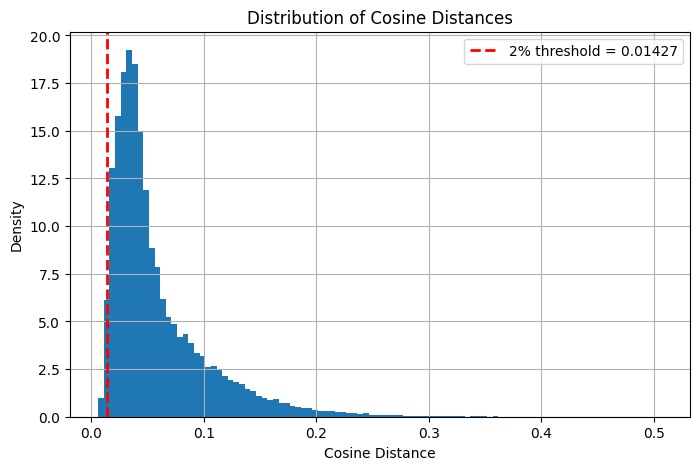

In [60]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8,5))

plt.hist(
    q_arr,
    bins=100,
    density=True
)

thr2 = np.percentile(q_arr, 2)

plt.axvline(
    thr2,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'2% threshold = {thr2:.5f}'
)

plt.xlabel("Cosine Distance")
plt.ylabel("Density")
plt.title("Distribution of Cosine Distances")
plt.legend()
plt.grid(True)
plt.savefig(
    "cosine_distance_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

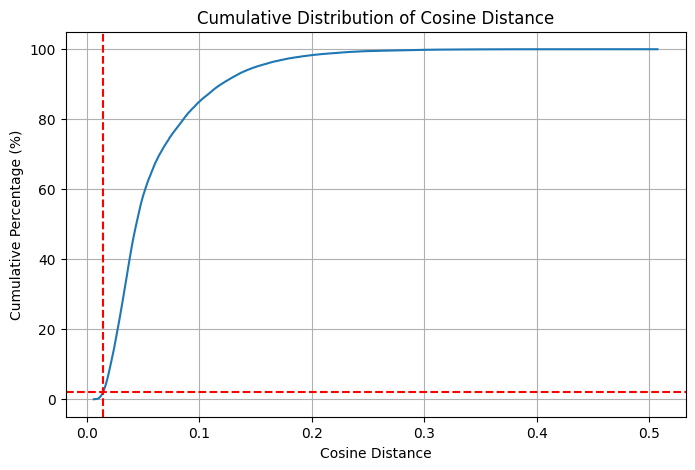

In [61]:
plt.figure(figsize=(8,5))

sorted_d = np.sort(q_arr)

cum = np.arange(1, len(sorted_d)+1) / len(sorted_d) * 100

plt.plot(sorted_d, cum)

plt.axhline(2, color='red', linestyle='--')
plt.axvline(np.percentile(q_arr,2), color='red', linestyle='--')

plt.xlabel("Cosine Distance")
plt.ylabel("Cumulative Percentage (%)")
plt.title("Cumulative Distribution of Cosine Distance")

plt.grid(True)
plt.savefig(
    "cosine_distance_cdf.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [62]:
import pandas as pd

results = [
    {
        "Method": "Original",
        "Covariance Before": 18.443347,
        "Covariance After": 18.443347,
        "Subspace Before": 6.183670,
        "Subspace After": 6.183670
    },
    {
        "Method": "SA (d=8)",
        "Covariance Before": 18.443347,
        "Covariance After": 12.099832,  
        "Subspace Before": 6.183670,       
        "Subspace After": 0.553499
    },
    {
        "Method": "TCA (d=10)",
        "Covariance Before": 18.443347,
        "Covariance After": 6.182421,
        "Subspace Before": 6.183670,       
        "Subspace After": 0.868664
    },
    {
        "Method": "CORAL",
        "Covariance Before": 18.443347,
        "Covariance After": 0.001750,
        "Subspace Before": 6.183670,
        "Subspace After": 0.000272
    },
    {
        "Method": "CORAL + SA",
        "Covariance Before": 18.443347,
        "Covariance After": 3.902454,
        "Subspace Before": 6.183670,
        "Subspace After": 0.000169
    },
    {
        "Method": "SA + CORAL",
        "Covariance Before": 18.443347,
        "Covariance After": 5.414516,
        "Subspace Before": 6.183670,
        "Subspace After": 0.544939
    }
]

df = pd.DataFrame(results)

df["Covariance Improvement (%)"] = (
    (df["Covariance Before"] - df["Covariance After"])
    / df["Covariance Before"] * 100
)

df["Subspace Improvement (%)"] = (
    (df["Subspace Before"] - df["Subspace After"])
    / df["Subspace Before"] * 100
)

df = df.round(4)

display(df)

,Method,Covariance Before,Covariance After,Subspace Before,Subspace After,Covariance Improvement (%),Subspace Improvement (%)
0,Original,18.4433,18.4433,6.1837,6.1837,0.0000,0.0000
1,SA (d=8),18.4433,12.0998,6.1837,0.5535,34.3946,91.0490
2,TCA (d=10),18.4433,6.1824,6.1837,0.8687,66.4789,85.9523
3,CORAL,18.4433,0.0018,6.1837,0.0003,99.9905,99.9956
4,CORAL + SA,18.4433,3.9025,6.1837,0.0002,78.8409,99.9973
5,SA + CORAL,18.4433,5.4145,6.1837,0.5449,70.6424,91.1875


In [63]:
df.to_csv("domain_adaptation_comparison.csv", index=False)

In [64]:
df.to_excel("domain_adaptation_comparison.xlsx", index=False)

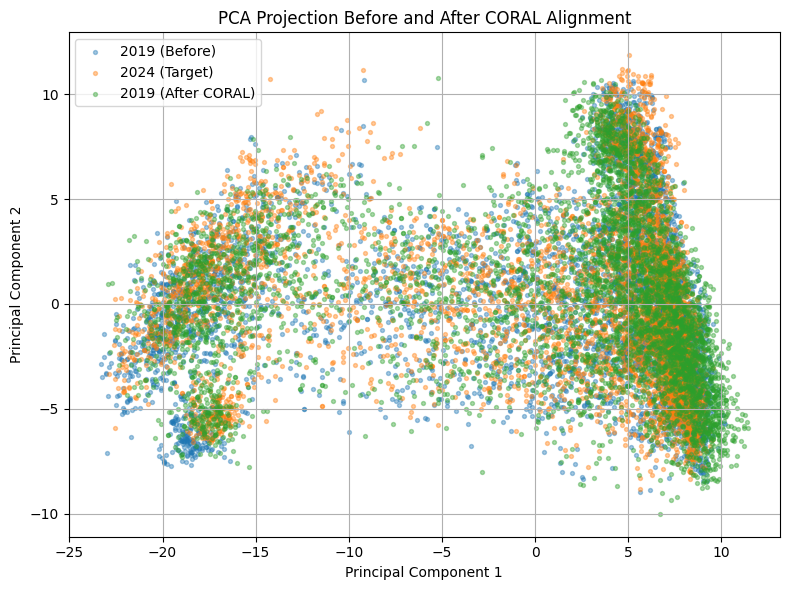

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Apply CORAL
X19_coral = coral_apply(X19s, align_params)

# Fit PCA on combined ORIGINAL datasets
X_all = np.vstack([X19s, X24s])

pca = PCA(n_components=2, random_state=42)
pca.fit(X_all)

# Project all datasets into the same PCA space
P19 = pca.transform(X19s)
P24 = pca.transform(X24s)
P19c = pca.transform(X19_coral)

# Reduce clutter if necessary
N = min(5000, len(P19))
idx = np.random.RandomState(42).choice(len(P19), N, replace=False)

plt.figure(figsize=(8,6))

plt.scatter(
    P19[idx,0],
    P19[idx,1],
    s=8,
    alpha=0.4,
    label='2019 (Before)'
)

plt.scatter(
    P24[idx,0],
    P24[idx,1],
    s=8,
    alpha=0.4,
    label='2024 (Target)'
)

plt.scatter(
    P19c[idx,0],
    P19c[idx,1],
    s=8,
    alpha=0.4,
    label='2019 (After CORAL)'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection Before and After CORAL Alignment")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("PCA_CORAL_alignment.png", dpi=300)
plt.show()

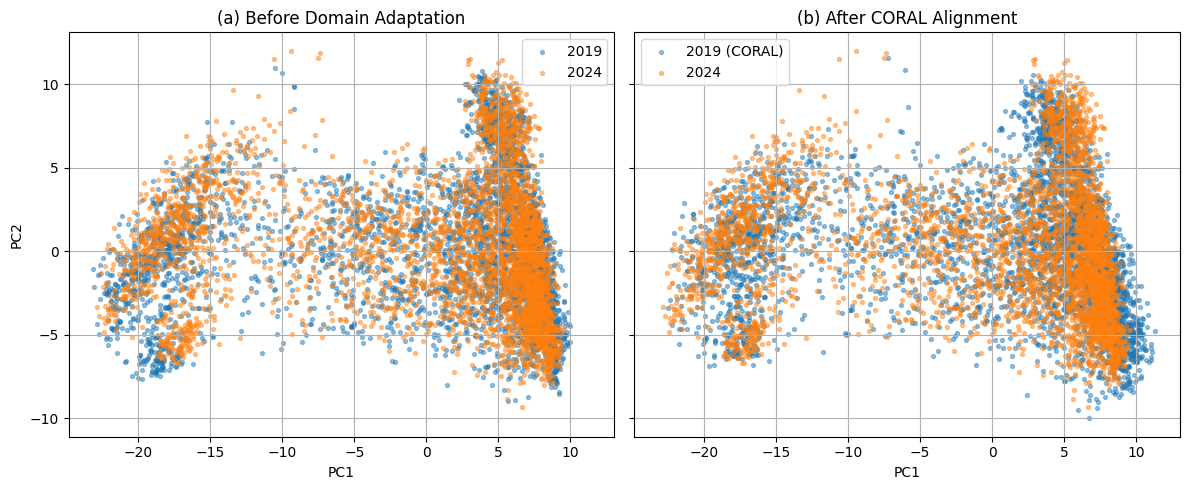

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ----------------------------
# Apply CORAL
# ----------------------------
X19_coral = coral_apply(X19s, align_params)

# ----------------------------
# Fit PCA on ORIGINAL domains
# ----------------------------
X_all = np.vstack((X19s, X24s))

pca = PCA(n_components=2, random_state=42)
pca.fit(X_all)

P19 = pca.transform(X19s)
P24 = pca.transform(X24s)
P19c = pca.transform(X19_coral)

# ----------------------------
# Random subset for visualization
# ----------------------------
N = min(4000, len(P19))

rng = np.random.default_rng(42)
idx = rng.choice(len(P19), N, replace=False)

# ----------------------------
# Plot
# ----------------------------
fig, ax = plt.subplots(1, 2, figsize=(12,5), sharex=True, sharey=True)

# BEFORE
ax[0].scatter(
    P19[idx,0], P19[idx,1],
    s=8, alpha=0.45,
    label="2019"
)

ax[0].scatter(
    P24[idx,0], P24[idx,1],
    s=8, alpha=0.45,
    label="2024"
)

ax[0].set_title("(a) Before Domain Adaptation")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].legend()
ax[0].grid(True)

# AFTER
ax[1].scatter(
    P19c[idx,0], P19c[idx,1],
    s=8, alpha=0.45,
    label="2019 (CORAL)"
)

ax[1].scatter(
    P24[idx,0], P24[idx,1],
    s=8, alpha=0.45,
    label="2024"
)

ax[1].set_title("(b) After CORAL Alignment")
ax[1].set_xlabel("PC1")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()

plt.savefig(
    "PCA_Before_After_CORAL.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# ----------------------------
# CORAL output
# ----------------------------
X19_coral = coral_apply(X19s, align_params)

# ----------------------------
# Sample points for speed
# ----------------------------
N = min(3000, len(X19s))

rng = np.random.default_rng(42)
idx = rng.choice(len(X19s), N, replace=False)

S19 = X19s[idx]
S24 = X24s[idx]
S19c = X19_coral[idx]

# ----------------------------
# Combine datasets
# ----------------------------
X = np.vstack([S19, S24, S19c])

labels = (
    ["2019"] * N +
    ["2024"] * N +
    ["2019_CORAL"] * N
)

# ----------------------------
# Run ONE t-SNE
# ----------------------------
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

Y = tsne.fit_transform(X)

# Split embeddings
Y19 = Y[:N]
Y24 = Y[N:2*N]
Y19c = Y[2*N:]

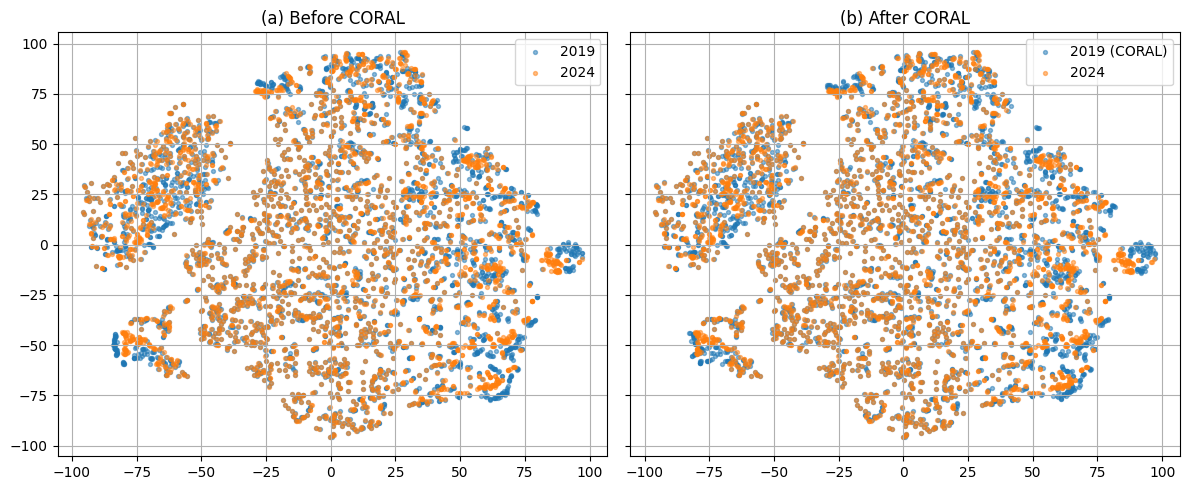

In [68]:
fig, ax = plt.subplots(1,2,figsize=(12,5),sharex=True,sharey=True)

# BEFORE
ax[0].scatter(Y19[:,0],Y19[:,1],s=8,alpha=0.5,label="2019")
ax[0].scatter(Y24[:,0],Y24[:,1],s=8,alpha=0.5,label="2024")

ax[0].set_title("(a) Before CORAL")
ax[0].legend()
ax[0].grid(True)

# AFTER
ax[1].scatter(Y19c[:,0],Y19c[:,1],s=8,alpha=0.5,label="2019 (CORAL)")
ax[1].scatter(Y24[:,0],Y24[:,1],s=8,alpha=0.5,label="2024")

ax[1].set_title("(b) After CORAL")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()

plt.savefig(
    "tsne_before_after_coral.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [69]:
from sklearn.decomposition import PCA

pca = PCA(n_components=20, random_state=42)

X = pca.fit_transform(X)

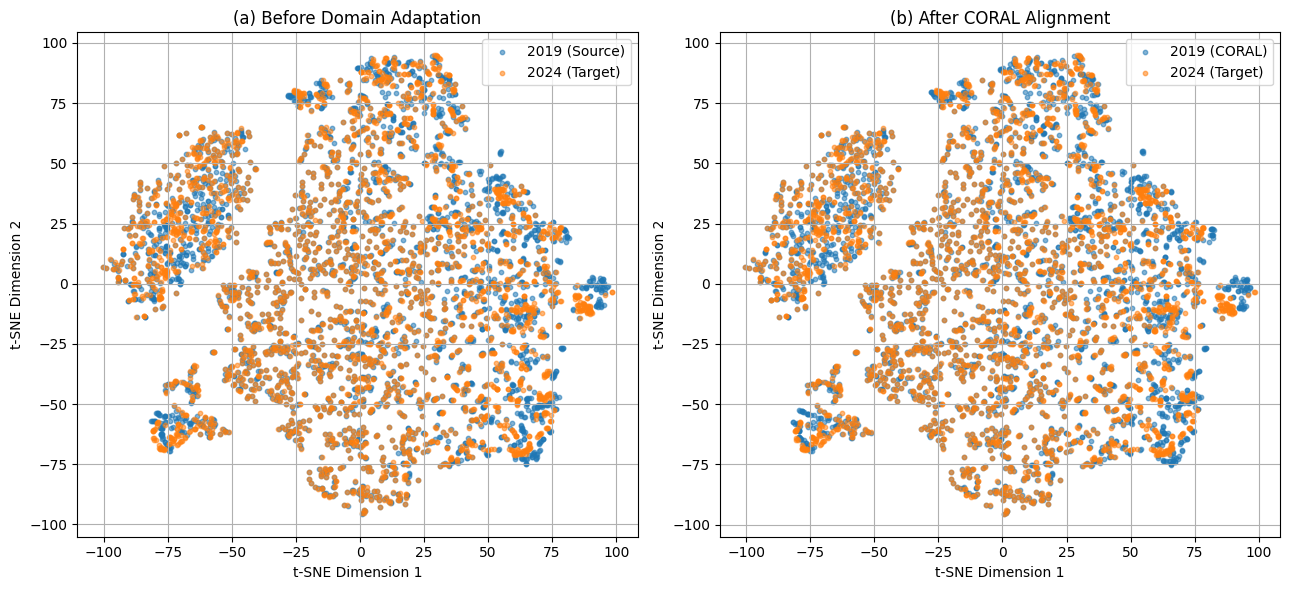

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ==========================================================
# 1. CORAL Alignment
# ==========================================================
X19_coral = coral_apply(X19s, align_params)

# ==========================================================
# 2. Random sampling (for speed)
# ==========================================================
N = min(3000, len(X19s))

rng = np.random.default_rng(42)
idx = rng.choice(len(X19s), N, replace=False)

S19 = X19s[idx]
S24 = X24s[idx]
S19c = X19_coral[idx]

# ==========================================================
# 3. Combine datasets
# ==========================================================
X_all = np.vstack([S19, S24, S19c])

# ==========================================================
# 4. PCA (64 bands -> 20 PCs)
# ==========================================================
pca = PCA(n_components=20, random_state=42)
X_pca = pca.fit_transform(X_all)

# ==========================================================
# 5. t-SNE
# ==========================================================
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_pca)

# ==========================================================
# 6. Split embeddings
# ==========================================================
Y19  = X_tsne[:N]
Y24  = X_tsne[N:2*N]
Y19c = X_tsne[2*N:]

# ==========================================================
# 7. Plot
# ==========================================================
fig, ax = plt.subplots(1, 2, figsize=(13, 6))

# ---------- BEFORE ----------
ax[0].scatter(
    Y19[:,0], Y19[:,1],
    s=10,
    alpha=0.55,
    label="2019 (Source)"
)

ax[0].scatter(
    Y24[:,0], Y24[:,1],
    s=10,
    alpha=0.55,
    label="2024 (Target)"
)

ax[0].set_title("(a) Before Domain Adaptation")
ax[0].set_xlabel("t-SNE Dimension 1")
ax[0].set_ylabel("t-SNE Dimension 2")
ax[0].grid(True)
ax[0].legend()

# ---------- AFTER ----------
ax[1].scatter(
    Y19c[:,0], Y19c[:,1],
    s=10,
    alpha=0.55,
    label="2019 (CORAL)"
)

ax[1].scatter(
    Y24[:,0], Y24[:,1],
    s=10,
    alpha=0.55,
    label="2024 (Target)"
)

ax[1].set_title("(b) After CORAL Alignment")
ax[1].set_xlabel("t-SNE Dimension 1")
ax[1].set_ylabel("t-SNE Dimension 2")
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()

plt.savefig(
    "tSNE_CORAL_Before_After.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

C:\Users\snvra\AppData\Local\Temp\ipykernel_24180\455045070.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


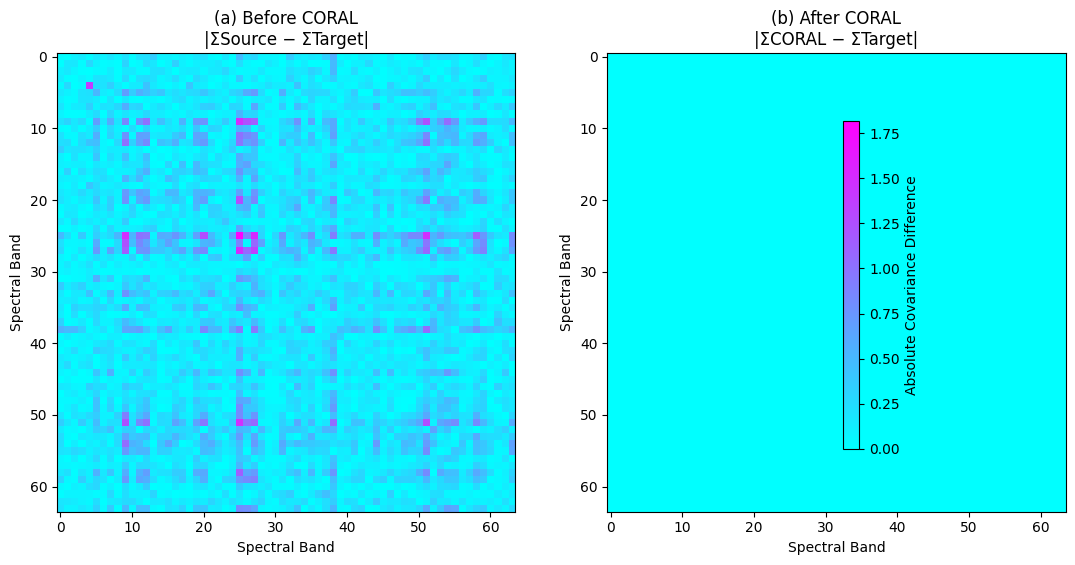

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Covariance matrices
# ==========================================
cov_source = np.cov(X19s.T)
cov_target = np.cov(X24s.T)

# CORAL transformed source
X19_coral = coral_apply(X19s, align_params)
cov_coral = np.cov(X19_coral.T)

# ==========================================
# Difference matrices
# ==========================================
diff_before = np.abs(cov_source - cov_target)
diff_after  = np.abs(cov_coral - cov_target)

# Same color scale
vmin = 0
vmax = max(diff_before.max(), diff_after.max())

# ==========================================
# Plot
# ==========================================
fig, ax = plt.subplots(1,2, figsize=(11,5))

im1 = ax[0].imshow(
    diff_before,
    cmap="cool",
    vmin=vmin,
    vmax=vmax
)

ax[0].set_title("(a) Before CORAL\n|ΣSource − ΣTarget|")
ax[0].set_xlabel("Spectral Band")
ax[0].set_ylabel("Spectral Band")

im2 = ax[1].imshow(
    diff_after,
    cmap="cool",
    vmin=vmin,
    vmax=vmax
)

ax[1].set_title("(b) After CORAL\n|ΣCORAL − ΣTarget|")
ax[1].set_xlabel("Spectral Band")
ax[1].set_ylabel("Spectral Band")

cbar = fig.colorbar(im1, ax=ax.ravel().tolist(), shrink=0.85)
cbar.set_label("Absolute Covariance Difference")

plt.tight_layout()

plt.savefig(
    "Covariance_Difference_Matrices.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

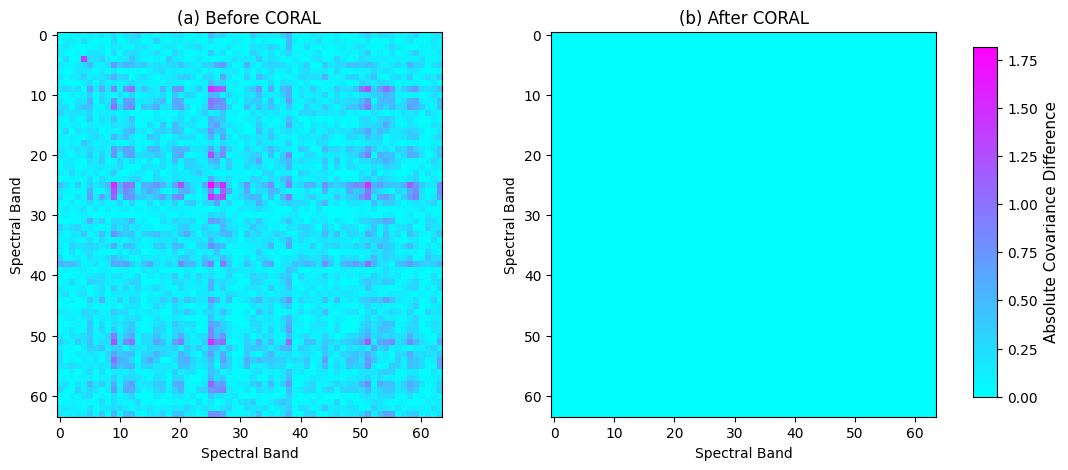

In [77]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# Compute covariance matrices
# =====================================================
cov_source = np.cov(X19s.T)
cov_target = np.cov(X24s.T)

# CORAL aligned source
X19_coral = coral_apply(X19s, align_params)
cov_coral = np.cov(X19_coral.T)

# =====================================================
# Difference matrices
# =====================================================
diff_before = np.abs(cov_source - cov_target)
diff_after  = np.abs(cov_coral - cov_target)

# Common color scale
vmin = 0
vmax = max(diff_before.max(), diff_after.max())

# =====================================================
# Plot
# =====================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=(12,5)
)

# -------------------------
# Before CORAL
# -------------------------
im = axes[0].imshow(
    diff_before,
    cmap="cool",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

axes[0].set_title("(a) Before CORAL", fontsize=12)
axes[0].set_xlabel("Spectral Band")
axes[0].set_ylabel("Spectral Band")

# -------------------------
# After CORAL
# -------------------------
axes[1].imshow(
    diff_after,
    cmap="cool",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

axes[1].set_title("(b) After CORAL", fontsize=12)
axes[1].set_xlabel("Spectral Band")
axes[1].set_ylabel("Spectral Band")

# =====================================================
# Space for colorbar
# =====================================================
plt.subplots_adjust(right=0.88)

# Colorbar axis
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.70])

cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(
    "Absolute Covariance Difference",
    fontsize=11
)

# =====================================================
# Save
# =====================================================
plt.savefig(
    "Covariance_Difference_Matrices.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

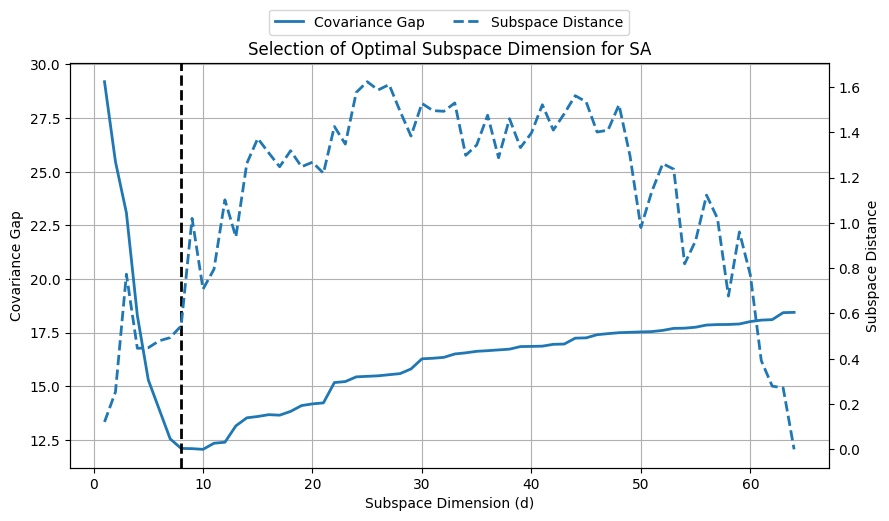

In [102]:
import pandas as pd
import matplotlib.pyplot as plt

# Read results
df = pd.read_csv(r"C:\Users\snvra\NISAR_Data_project/output_plots/SA_dimension_sweep.csv")

selected_d = 8      # Change to your chosen value

fig, ax1 = plt.subplots(figsize=(9,5))

# Covariance Gap
line1=ax1.plot(
    df["d"],
    df["cov_after"],
    linewidth=2,
    label="Covariance Gap"
)

ax1.set_xlabel("Subspace Dimension (d)")
ax1.set_ylabel("Covariance Gap")
ax1.grid(True)

# Selected dimension
vline=ax1.axvline(
    selected_d,
    linestyle="--",
    linewidth=2,
    color="black"
)

# Second axis
ax2 = ax1.twinx()

line2=ax2.plot(
    df["d"],
    df["sa_after"],
    linewidth=2,
    linestyle="--",
    label="Subspace Distance"
)

ax2.set_ylabel("Subspace Distance")

plt.title("Selection of Optimal Subspace Dimension for SA")

plt.tight_layout()
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=3,
    frameon=True
)
plt.savefig("SA_dimension_selection.png", dpi=600)
plt.show()

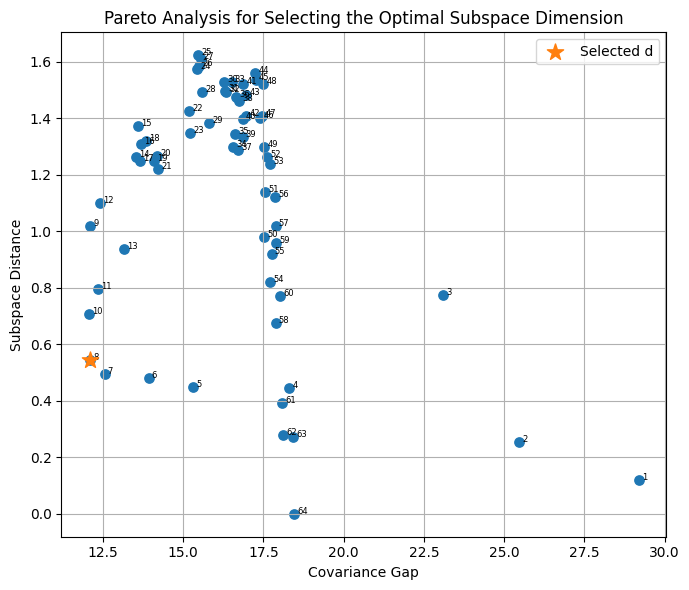

In [104]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\snvra\NISAR_Data_project/output_plots/SA_dimension_sweep.csv")

plt.figure(figsize=(7,6))

plt.scatter(
    df["cov_after"],
    df["sa_after"],
    s=45
)

# Label every point
for _, row in df.iterrows():
    plt.text(
        row["cov_after"]+0.1,
        row["sa_after"],
        str(int(row["d"])),
        fontsize=6
    )

# Highlight selected d
selected = df[df["d"]==8]

plt.scatter(
    selected["cov_after"],
    selected["sa_after"],
    s=150,
    marker="*",
    label="Selected d",
    zorder=5
)

plt.xlabel("Covariance Gap")
plt.ylabel("Subspace Distance")

plt.title("Pareto Analysis for Selecting the Optimal Subspace Dimension")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    "SA_pareto_dimension_selection.png",
    dpi=600
)

plt.show()

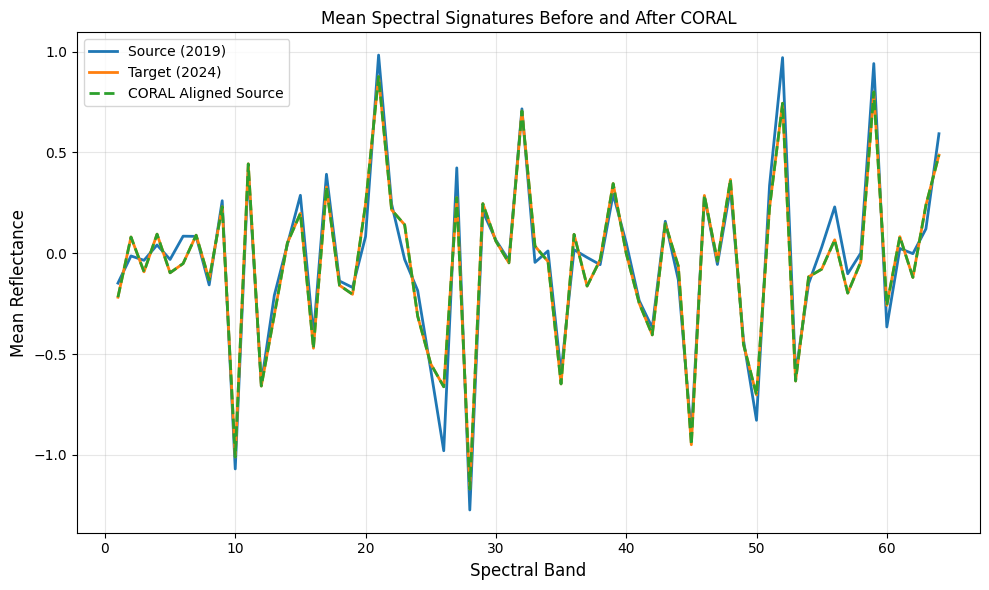

In [99]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------
# Mean spectra
# -------------------------------------------------------
mean_source = np.mean(X19s, axis=0)
mean_target = np.mean(X24s, axis=0)

# CORAL aligned source
X19_coral = coral_apply(X19s, align_params)
mean_coral = np.mean(X19_coral, axis=0)

bands = np.arange(1, len(mean_source)+1)

# -------------------------------------------------------
# Plot
# -------------------------------------------------------
plt.figure(figsize=(10,6))

plt.plot(
    bands,
    mean_source,
    linewidth=2,
    label="Source (2019)"
)

plt.plot(
    bands,
    mean_target,
    linewidth=2,
    label="Target (2024)"
)

plt.plot(
    bands,
    mean_coral,
    linewidth=2,
    linestyle="--",
    label="CORAL Aligned Source"
)

plt.xlabel("Spectral Band", fontsize=12)
plt.ylabel("Mean Reflectance", fontsize=12)

plt.title("Mean Spectral Signatures Before and After CORAL")

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    "Mean_Spectral_Curves_CORAL.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

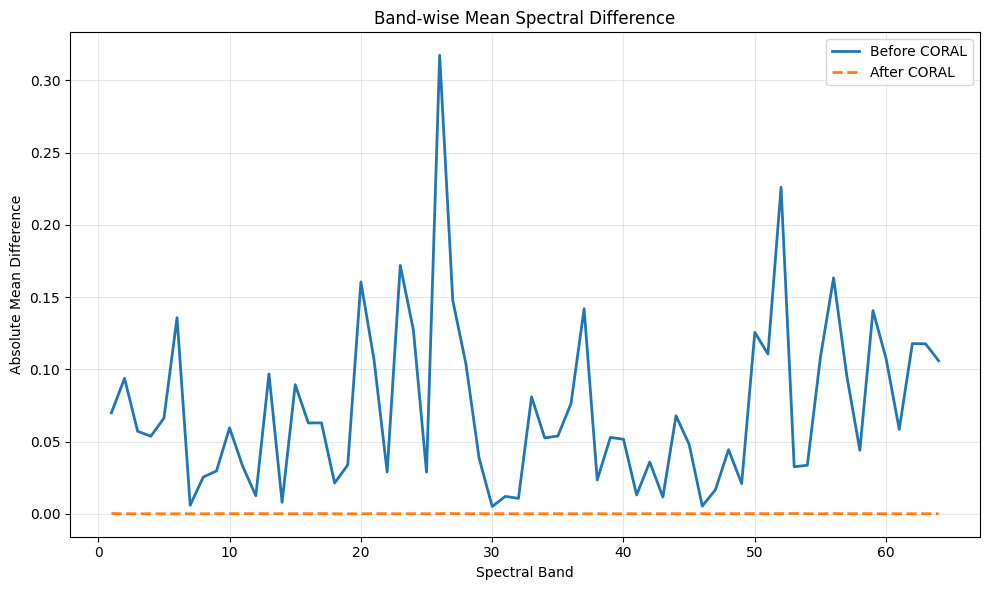

In [101]:
diff_source = np.abs(mean_source - mean_target)
diff_coral  = np.abs(mean_coral - mean_target)

plt.figure(figsize=(10,6))

plt.plot(
    bands,
    diff_source,
    linewidth=2,
    label="Before CORAL"
)

plt.plot(
    bands,
    diff_coral,
    linewidth=2,
    linestyle="--",
    label="After CORAL"
)

plt.xlabel("Spectral Band")
plt.ylabel("Absolute Mean Difference")

plt.title("Band-wise Mean Spectral Difference")

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()
plt.savefig(
    "Mean_Spectral_difference_CORAL.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()